# Factors Affecting Formula 1 Lap Times

**Exploratory data analysis · 1996–2026 lap records · 2024 team comparisons**

### Research question
**Which factors are associated with differences in Formula 1 lap times?**

### Scope
This notebook presents four analyses: **(1) circuit characteristics, (2) driver performance, (3) constructor-associated performance, and (4) race progression**. Pit-stop records are used to identify laps for filtering, but a dedicated pit-stop impact analysis is **not included** in this version.

### Approach
Lap times (in seconds) are merged with circuit metadata, race results, and recorded pit stops. Selected exploratory pace laps are compared within races or normalized to a relevant reference. Results are **associations, not proof of causation**.

> **Reproducibility:** Run the notebook from the `f1-driver-vs-car` project in VS Code or Jupyter with the CSV files in their existing project folders. The saved charts below come from the previously executed notebook; rerun all cells locally to refresh them after any dataset changes.

## Data preparation

### Data sources and project layout

| Source | Expected location | Role |
|---|---|---|
| Cleaned lap times | `data/processed/laps/lap_times_cleaned.csv` | Driver, race, lap number and lap time (seconds) |
| Circuit metadata | `data/processed/**/wikipedia_circuits_cleaned.csv` | Circuit type, length and turns |
| Race results | `data/raw/results.csv` | Constructor associated with each driver and race |
| Pit stops | `data/raw/pitstops.csv` | Pit-stop marker (available from 2011 onward) |

We retain **one row per driver–race–lap**. The original cleaned lap-time file is not modified.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook is opened from the root or a subfolder.
project_root = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "data" / "processed" / "laps" / "lap_times_cleaned.csv").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Missing data/processed/laps/lap_times_cleaned.csv. "
        "Open this notebook inside the F1 project and prepare the cleaned CSV first."
    )

df = pd.read_csv(
    project_root / "data" / "processed" / "laps" / "lap_times_cleaned.csv",
    low_memory=False,
)
print(f"Loaded {len(df):,} cleaned lap records.")

Loaded 639,293 cleaned lap records.


In [3]:
# Match circuit names from two sources, including known naming differences.
lap_circuits = df[["circuit_id", "circuit_name"]].drop_duplicates()
wiki_files = list((project_root / "data" / "processed").rglob("wikipedia_circuits_cleaned.csv"))
if len(wiki_files) != 1:
    raise ValueError(f"Expected one Wikipedia circuits CSV, found {len(wiki_files)}.")

wiki = pd.read_csv(wiki_files[0])
wiki["Circuit"] = (
    wiki["Circuit"]
    .str.replace(r"\[[^\]]*\]", "", regex=True)
    .str.replace(r"[*†‡]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
name_to_id = dict(zip(lap_circuits["circuit_name"], lap_circuits["circuit_id"]))
name_to_id.update({
    "Albert Park Circuit": "albert_park",
    "Algarve International Circuit": "portimao",
    "Autódromo Oscar y Juan Gálvez": "galvez",
    "Autodromo Internazionale Enzo e Dino Ferrari": "imola",
    "Autodromo José Carlos Pace": "interlagos",
    "Circuito Permanente de Jerez": "jerez",
    "Circuit Zandvoort": "zandvoort",
    "Las Vegas Strip Circuit": "vegas",
    "Suzuka International Racing Course": "suzuka",
    "Korea International Circuit": "yeongam",
})
wiki["circuit_id"] = wiki["Circuit"].map(name_to_id)

circuit_features = (
    wiki.loc[wiki["circuit_id"].notna(),
             ["circuit_id", "Circuit", "Type", "Direction", "Turns", "Circuit_length_km"]]
    .rename(columns={
        "Circuit": "wiki_circuit_name",
        "Type": "circuit_type",
        "Direction": "circuit_direction",
        "Turns": "wiki_turns",
        "Circuit_length_km": "wiki_length_km",
    })
    .copy()
)
for column in ["wiki_turns", "wiki_length_km"]:
    circuit_features[column] = pd.to_numeric(circuit_features[column], errors="raise")

# 'many_to_one' protects against accidental duplication of lap records.
laps_merged = df.merge(circuit_features, on="circuit_id", how="left", validate="many_to_one")
if laps_merged["wiki_length_km"].isna().any():
    raise ValueError("Some circuits lack matching length data; review circuit-name mapping.")
print(f"Circuit metadata matched: {circuit_features['circuit_id'].nunique()} circuits.")

Circuit metadata matched: 42 circuits.


In [4]:
# Add a constructor to each driver in each race.
results = pd.read_csv(project_root / "data" / "raw" / "results.csv", low_memory=False)
team_columns = ["season", "round", "driver_id", "constructor_id", "constructor_name"]
laps_with_teams = laps_merged.merge(
    results[team_columns], on=["season", "round", "driver_id"],
    how="left", validate="many_to_one",
)

# Pit stops: aggregate multiple stops on a lap before merging to avoid row inflation.
pitstops = pd.read_csv(project_root / "data" / "raw" / "pitstops.csv", low_memory=False)
pit_key = ["season", "round", "driver_id", "lap"]
pit_laps = (
    pitstops.groupby(pit_key, as_index=False)
    .agg(recorded_pit_stops=("stop", "size"))
)
laps_with_pits = laps_with_teams.merge(
    pit_laps, on=pit_key, how="left", validate="many_to_one",
)
laps_with_pits["has_recorded_pit_stop"] = (
    laps_with_pits["recorded_pit_stops"].notna().astype("boolean")
)
laps_with_pits["recorded_pit_stops"] = laps_with_pits["recorded_pit_stops"].astype("Int64")
# Unknown is not the same as zero: pit-stop coverage begins in 2011.
laps_with_pits.loc[laps_with_pits["season"] < 2011, "has_recorded_pit_stop"] = pd.NA
print(f"Integrated dataset: {len(laps_with_pits):,} driver-lap records.")

Integrated dataset: 639,293 driver-lap records.


### Analysis sample and quality safeguards

The original dataset is preserved. For exploratory race-pace analysis, we:

- exclude first laps and **matched** pit-stop laps;
- flag *candidate mass delays* when ≥5 drivers and ≥50% of drivers on the same race lap record times over 100% above that race's median;
- retain laps within **±20% of the race median** as a pragmatic initial pace sample.

These rules are **heuristics**, not confirmed labels for every red flag, safety car or pit event. We do not infer that missing pre-2011 pit records mean that no stop occurred. All filters should be revisited for a formal causal or predictive study.

In [5]:
# Essential safeguards only (the exploratory diagnostic cells are omitted here).
required = [
    "season", "round", "driver_id", "lap", "lap_time_seconds",
    "constructor_id", "circuit_id", "circuit_type", "wiki_length_km", "wiki_turns",
]
missing = [c for c in required if c not in laps_with_pits.columns]
if missing:
    raise ValueError(f"Missing analysis columns: {missing}")
if laps_with_pits[required].isna().any().any():
    raise ValueError("Missing values in required analysis columns.")
if laps_with_pits.duplicated(["season", "round", "driver_id", "lap"]).any():
    raise ValueError("Duplicate driver-race-lap combinations.")
if (laps_with_pits["lap_time_seconds"] <= 0).any():
    raise ValueError("Nonpositive lap times detected.")

features = laps_with_pits.copy()
features["is_first_lap"] = features["lap"].eq(1)
features["race_median_seconds"] = features.groupby(["season", "round"])["lap_time_seconds"].transform("median")
features["lap_delta_seconds"] = features["lap_time_seconds"] - features["race_median_seconds"]
features["lap_relative_pct"] = 100 * features["lap_delta_seconds"] / features["race_median_seconds"]

# Flag shared extreme delays without deleting source rows.
race_lap_keys = ["season", "round", "lap"]
features["very_slow_lap"] = features["lap_relative_pct"].gt(100)
lap_events = (
    features.groupby(race_lap_keys, as_index=False)
    .agg(total_drivers=("driver_id", "size"), affected_drivers=("very_slow_lap", "sum"))
)
lap_events["affected_fraction"] = lap_events["affected_drivers"] / lap_events["total_drivers"]
flagged_keys = lap_events.loc[
    lap_events["affected_drivers"].ge(5) & lap_events["affected_fraction"].ge(0.5),
    race_lap_keys,
]
features["is_mass_delay_candidate"] = pd.MultiIndex.from_frame(
    features[race_lap_keys]
).isin(pd.MultiIndex.from_frame(flagged_keys))

is_recorded_pit = features["has_recorded_pit_stop"].fillna(False).astype(bool)
pace_mask = (
    ~features["is_first_lap"]
    & ~features["is_mass_delay_candidate"]
    & ~is_recorded_pit
    & features["lap_relative_pct"].between(-20, 20)
)
pace_laps = features.loc[pace_mask].copy()
if pace_laps.empty:
    raise ValueError("No race-pace observations remain after filtering.")
print(f"Raw driver laps: {len(features):,}")
print(f"Candidate mass-delay race-laps: {len(flagged_keys):,}")
print(f"Filtered pace laps: {len(pace_laps):,}")

Raw driver laps: 639,293
Candidate mass-delay race-laps: 56
Filtered pace laps: 577,990


---

## 1. Circuit Characteristics

**Question:** How are circuit length, number of turns and circuit type related to lap times?

**Method:** Compute a median lap time for each race, then summarize across races at the circuit level. We compare absolute lap time with circuit length, and distance-normalized time (**seconds per km**) with turns and circuit type. Each circuit enters the correlation and type-comparison summaries once.

In [6]:
# Aggregate to one representative value per circuit.
race_summary = (
    pace_laps.groupby(
        ["season", "round", "circuit_id", "circuit_type", "wiki_length_km", "wiki_turns"],
        as_index=False,
    )
    .agg(median_lap_seconds=("lap_time_seconds", "median"), n_laps=("lap_time_seconds", "size"))
)
race_summary["seconds_per_km"] = race_summary["median_lap_seconds"] / race_summary["wiki_length_km"]
circuit_summary = (
    race_summary.groupby(["circuit_id", "circuit_type", "wiki_length_km", "wiki_turns"], as_index=False)
    .agg(
        median_lap_seconds=("median_lap_seconds", "median"),
        seconds_per_km=("seconds_per_km", "median"),
        n_races=("season", "size"),
    )
)
print(f"Circuits analyzed: {len(circuit_summary)}")

Circuits analyzed: 42


### Visual evidence

1. **Circuit length vs lap time:** longer layouts generally imply longer absolute lap times.
2. **Turns vs seconds/km:** check whether turn count adds a visible linear pattern after adjusting for distance.
3. **Circuit type:** compare the distribution across permanent and street circuits.

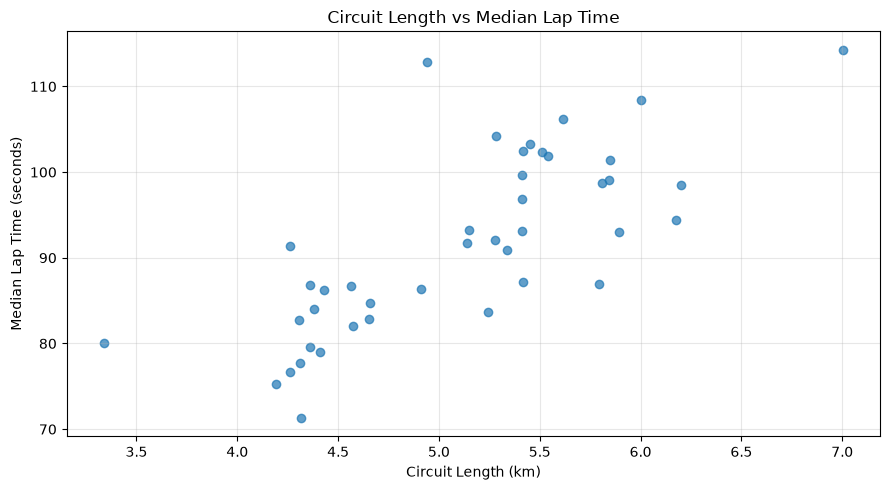

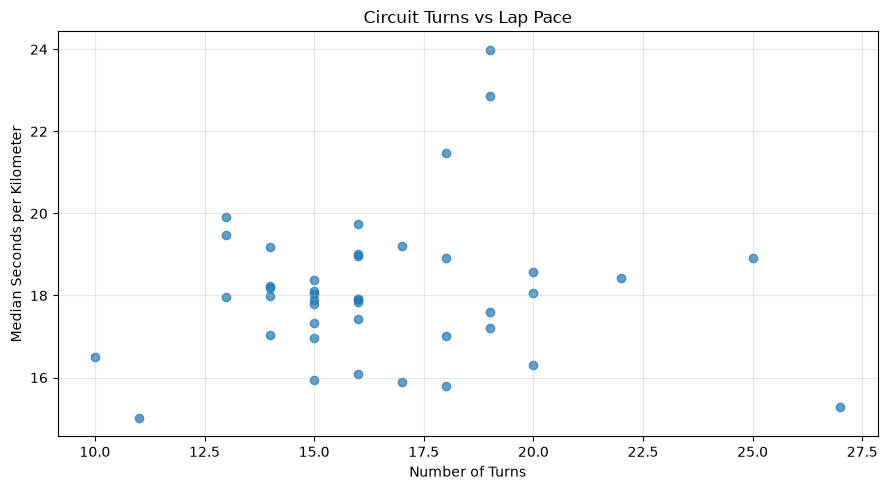

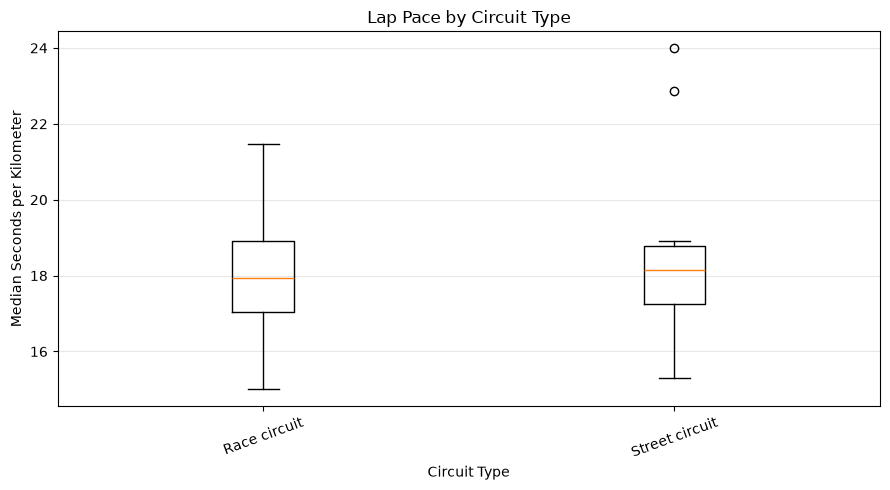

In [7]:

import matplotlib.pyplot as plt

# GRAPH 1: CIRCUIT LENGTH VS LAP TIME

plt.figure(figsize=(9, 5))

plt.scatter(
    circuit_summary["wiki_length_km"],
    circuit_summary["median_lap_seconds"],
    alpha=0.7
)

plt.xlabel("Circuit Length (km)")
plt.ylabel("Median Lap Time (seconds)")
plt.title("Circuit Length vs Median Lap Time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# GRAPH 2: TURNS VS SECONDS PER KM

plt.figure(figsize=(9, 5))

plt.scatter(
    circuit_summary["wiki_turns"],
    circuit_summary["seconds_per_km"],
    alpha=0.7
)

plt.xlabel("Number of Turns")
plt.ylabel("Median Seconds per Kilometer")
plt.title("Circuit Turns vs Lap Pace")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



# GRAPH 3: CIRCUIT TYPE COMPARISON

groups = [
    group["seconds_per_km"].values
    for _, group in circuit_summary.groupby("circuit_type")
]

labels = [
    name
    for name, _ in circuit_summary.groupby("circuit_type")
]

plt.figure(figsize=(9, 5))

plt.boxplot(groups, tick_labels=labels)

plt.xlabel("Circuit Type")
plt.ylabel("Median Seconds per Kilometer")
plt.title("Lap Pace by Circuit Type")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



In [8]:

# CIRCUIT CORRELATIONS

length_corr = circuit_summary[
    "wiki_length_km"
].corr(circuit_summary["median_lap_seconds"])

turns_corr = circuit_summary[
    "wiki_turns"
].corr(circuit_summary["seconds_per_km"])

print("CORRELATION RESULTS")
print(f"Circuit length vs lap time: {length_corr:.3f}")
print(f"Turns vs seconds per km: {turns_corr:.3f}")

print("\nCIRCUIT TYPE SUMMARY")
display(
    circuit_summary.groupby("circuit_type")
    .agg(
        circuits=("circuit_id", "count"),
        median_seconds_per_km=("seconds_per_km", "median")
    )
    .round(3)
)


CORRELATION RESULTS
Circuit length vs lap time: 0.756
Turns vs seconds per km: 0.087

CIRCUIT TYPE SUMMARY


,circuits,median_seconds_per_km
circuit_type,,
Race circuit,32,17.945
Street circuit,10,18.149


### Conclusion — Circuit Characteristics

- **Circuit length:** a fairly strong positive association with median absolute lap time (**Pearson r = 0.756**). This is physically expected because longer circuits cover more distance.
- **Turns:** a very weak linear correlation with median seconds per km (**r = 0.087**). Corner geometry and speed matter more than turn count alone, and were not modeled here.
- **Circuit type:** street circuits had a slightly higher circuit-level median (**18.149 s/km**) than permanent circuits (**17.945 s/km**), about **1.14%** higher; statistical significance has not been established.

**Takeaway:** distance explains part of the variation in absolute lap time; turn count and circuit type alone offer much weaker descriptive signals. Wikipedia circuit dimensions may not reflect historic layouts.

---

## 2. Driver Performance — Teammate Comparisons

**Question:** Do teammates achieve different lap times in otherwise more comparable conditions?

**Method:** Pair two drivers from the same constructor, in the same race and lap number. Calculate each driver's difference from their teammate; negative values indicate a faster lap. To display season comparisons, use pairs with an absolute difference of **5 seconds or less** and retain drivers with at least **100 paired laps**. This filter is a presentation-oriented heuristic and may exclude genuine race-pace differences.

Matching teammates reduces some car differences but does **not** control for tires, traffic, damage or strategy.

In [9]:
# Match the two teammates for each constructor-race-lap.
pair_keys = ["season", "round", "constructor_id", "lap"]
driver_data = pace_laps.copy()
driver_data["drivers_in_pair"] = driver_data.groupby(pair_keys)["driver_id"].transform("nunique")
paired_laps = driver_data.loc[driver_data["drivers_in_pair"].eq(2)].copy()
if paired_laps.empty or (paired_laps.groupby(pair_keys).size() != 2).any():
    raise ValueError("Teammate pairing is incomplete or ambiguous.")

paired_laps["teammate_lap_seconds"] = (
    paired_laps.groupby(pair_keys)["lap_time_seconds"].transform("sum")
    - paired_laps["lap_time_seconds"]
)
paired_laps["driver_gap_seconds"] = (
    paired_laps["lap_time_seconds"] - paired_laps["teammate_lap_seconds"]
)
paired_laps["absolute_gap_seconds"] = paired_laps["driver_gap_seconds"].abs()
unique_pairs = paired_laps.drop_duplicates(subset=pair_keys)

print(f"Matched teammate lap pairs: {len(unique_pairs):,}")
print(f"Median absolute gap (unfiltered): {unique_pairs['absolute_gap_seconds'].median():.3f} s")

# Both driver-level records remain necessary for the signed-gap bar chart.
driver_analysis = paired_laps.loc[paired_laps["absolute_gap_seconds"].le(5)].copy()
driver_summary = (
    driver_analysis.groupby(["season", "constructor_id", "driver_id"], as_index=False)
    .agg(
        median_gap=("driver_gap_seconds", "median"),
        mean_gap=("driver_gap_seconds", "mean"),
        paired_laps=("driver_gap_seconds", "size"),
    )
)
driver_summary = driver_summary.loc[driver_summary["paired_laps"].ge(100)].copy()

Matched teammate lap pairs: 242,133
Median absolute gap (unfiltered): 0.611 s


### 2024 teammates

In the chart below, a **negative median gap** means that driver's laps were typically faster than their teammate's in the selected comparisons. These are **within-team** differences, not a cross-team driver ranking.

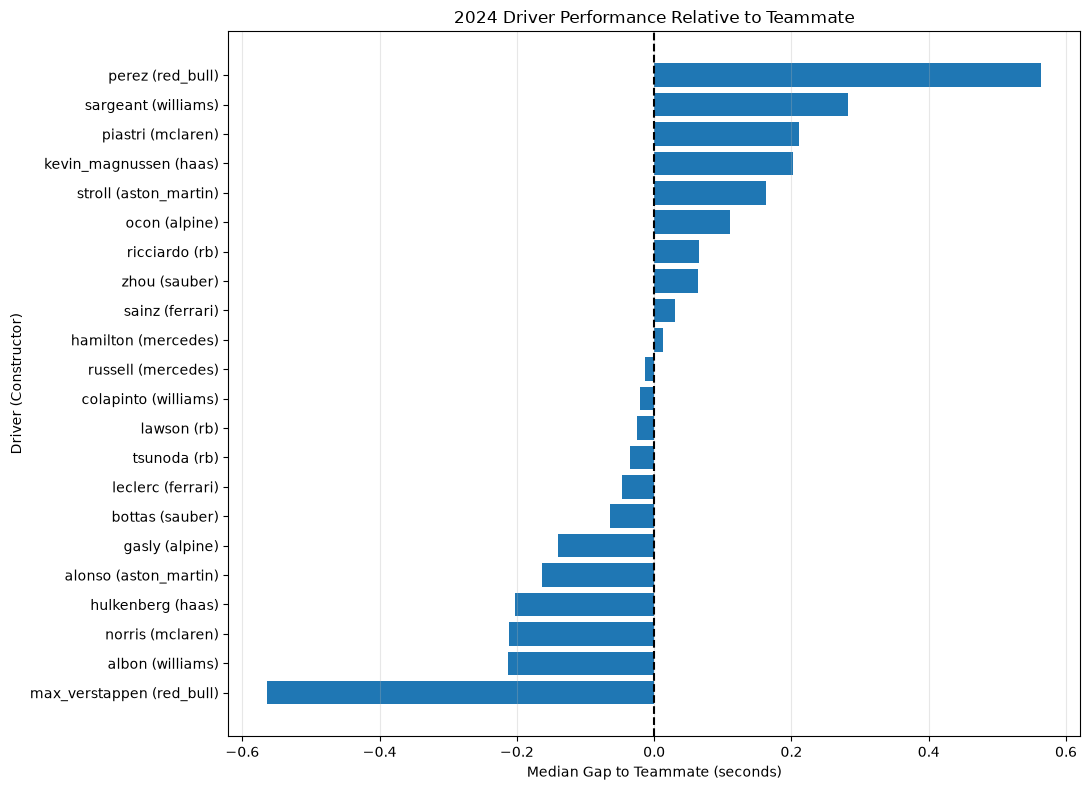


2024 DRIVER PERFORMANCE SUMMARY:
      driver_id constructor_id  median_gap  paired_laps
 max_verstappen       red_bull     -0.5640         1016
          albon       williams     -0.2125          794
         norris        mclaren     -0.2115         1236
     hulkenberg           haas     -0.2020         1090
         alonso   aston_martin     -0.1630         1020
          gasly         alpine     -0.1405          956
         bottas         sauber     -0.0640         1066
        leclerc        ferrari     -0.0470         1181
        tsunoda             rb     -0.0350         1013
         lawson             rb     -0.0250          235
      colapinto       williams     -0.0210          189
        russell       mercedes     -0.0130         1134
       hamilton       mercedes      0.0130         1134
          sainz        ferrari      0.0310         1135
           zhou         sauber      0.0640         1066
      ricciardo             rb      0.0660          778
           oco

In [10]:

# DRIVER PERFORMANCE IN THE 2024 SEASON

selected_season = 2024

season_drivers = driver_summary[
    driver_summary["season"] == selected_season
].copy()

season_drivers["label"] = (
    season_drivers["driver_id"]
    + " (" + season_drivers["constructor_id"] + ")"
)

season_drivers = season_drivers.sort_values(
    "median_gap"
)

if season_drivers.empty:
    raise ValueError("No drivers available for this season.")

plt.figure(figsize=(11, 8))

plt.barh(
    season_drivers["label"],
    season_drivers["median_gap"]
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Median Gap to Teammate (seconds)")
plt.ylabel("Driver (Constructor)")
plt.title("2024 Driver Performance Relative to Teammate")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\n2024 DRIVER PERFORMANCE SUMMARY:")
print(
    season_drivers[
        [
            "driver_id",
            "constructor_id",
            "median_gap",
            "paired_laps"
        ]
    ].to_string(index=False)
)


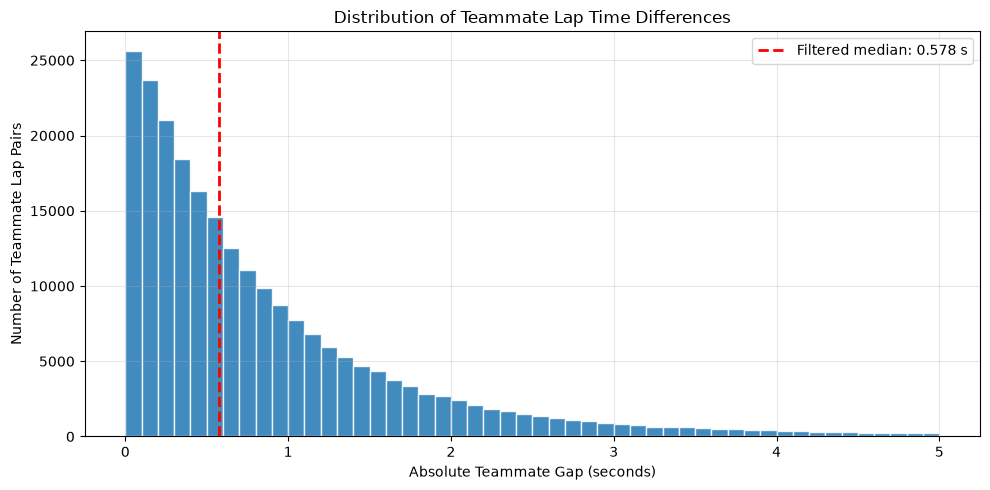

In [11]:
# Histogram: count each matched teammate pair once, not once per driver.
unique_filtered_pairs = driver_analysis.drop_duplicates(subset=pair_keys)
median_filtered_gap = unique_filtered_pairs["absolute_gap_seconds"].median()

plt.figure(figsize=(10, 5))
plt.hist(unique_filtered_pairs["absolute_gap_seconds"], bins=50, edgecolor="white", alpha=0.85)
plt.axvline(
    median_filtered_gap, color="red", linestyle="--", linewidth=2,
    label=f"Filtered median: {median_filtered_gap:.3f} s",
)
plt.xlabel("Absolute Teammate Gap (seconds)")
plt.ylabel("Number of Teammate Lap Pairs")
plt.title("Distribution of Teammate Lap Time Differences")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusion — Driver Performance

Across **242,133 unique teammate lap pairs**, the *unfiltered* median absolute time difference was **0.611 seconds**. In the selected 2024 comparisons, Verstappen's median advantage over Pérez was about **0.56 s**, and Norris's over Piastri about **0.21 s**; Hamilton and Russell were close to parity.

**Takeaway:** measurable teammate differences exist even within the same constructor. They cannot be attributed solely to driver skill because the data do not fully control for setup, strategy, tire compounds or traffic. The 5-second cutoff may influence season-level comparisons.

---

## 3. Constructor / Car-Associated Performance

**Question:** How does observed lap pace differ by constructor?

**Method:** Compare each lap with the **median lap time across drivers in the same race and lap number**. Aggregate first by driver-race, then by constructor-race to avoid allowing drivers with more recorded laps to dominate. Restrict the 2024 ranking to constructors with at least eight eligible races. In the constructor-race calculation, two eligible drivers and at least five constructors in the race are required.

Negative relative percentages indicate **faster** pace than the within-race-lap grid median. These figures describe the combined driver–car–team result, **not a causal estimate of car design alone**.

In [12]:

# ANALYSIS 3 - CONSTRUCTOR PERFORMANCE

import pandas as pd
import matplotlib.pyplot as plt

# Use previously prepared pace laps
car_data = pace_laps.copy()

race_lap_keys = ["season", "round", "lap"]

# 1. Keep laps with enough competitors
car_data["drivers_on_lap"] = (
    car_data.groupby(race_lap_keys)["driver_id"]
    .transform("nunique")
)

car_data = car_data[
    car_data["drivers_on_lap"] >= 6
].copy()

if car_data.empty:
    raise ValueError("No comparable laps found.")

# 2. Median lap time across competitors
car_data["grid_median_seconds"] = (
    car_data.groupby(race_lap_keys)["lap_time_seconds"]
    .transform("median")
)

# 3. Relative performance (%)
car_data["relative_pace_pct"] = (
    (
        car_data["lap_time_seconds"]
        / car_data["grid_median_seconds"]
    ) - 1
) * 100

# Negative = faster than grid median
# Positive = slower than grid median

# 4. One result per driver per race
driver_race = (
    car_data.groupby(
        ["season", "round", "constructor_id", "driver_id"],
        as_index=False
    )
    .agg(
        median_relative_pct=("relative_pace_pct", "median"),
        n_laps=("lap", "size")
    )
)

driver_race = driver_race[
    driver_race["n_laps"] >= 10
].copy()

# 5. Aggregate both teammates
team_race = (
    driver_race.groupby(
        ["season", "round", "constructor_id"],
        as_index=False
    )
    .agg(
        team_relative_pct=("median_relative_pct", "mean"),
        n_drivers=("driver_id", "nunique")
    )
)

# Require both teammates
team_race = team_race[
    team_race["n_drivers"] == 2
].copy()

# Require at least five teams per race
team_race["teams_compared"] = (
    team_race.groupby(["season", "round"])["constructor_id"]
    .transform("size")
)

team_race = team_race[
    team_race["teams_compared"] >= 5
].copy()

# Validation
if team_race.empty:
    raise ValueError("No valid team-race comparisons.")

assert team_race["team_relative_pct"].notna().all()

print("Constructor analysis passed!")
print("Comparable laps:", len(car_data))
print("Team-race observations:", len(team_race))

# 6. Analyze the 2024 season
selected_season = 2024

car_2024 = team_race[
    team_race["season"] == selected_season
].copy()

constructor_summary = (
    car_2024.groupby("constructor_id", as_index=False)
    .agg(
        median_relative_pct=("team_relative_pct", "median"),
        races=("round", "nunique")
    )
)

# Require at least eight comparable races
constructor_summary = constructor_summary[
    constructor_summary["races"] >= 8
].sort_values("median_relative_pct")

if constructor_summary.empty:
    raise ValueError("No constructors with enough 2024 races.")

print("\n2024 CONSTRUCTOR PERFORMANCE:")
print(constructor_summary.to_string(index=False))


Constructor analysis passed!
Comparable laps: 575953
Team-race observations: 5183

2024 CONSTRUCTOR PERFORMANCE:
constructor_id  median_relative_pct  races
       mclaren            -0.929581     24
       ferrari            -0.758811     24
      red_bull            -0.682148     21
      mercedes            -0.521756     23
  aston_martin             0.202931     20
          haas             0.273125     23
        alpine             0.372063     20
      williams             0.405951     19
            rb             0.420290     21
        sauber             0.778982     22


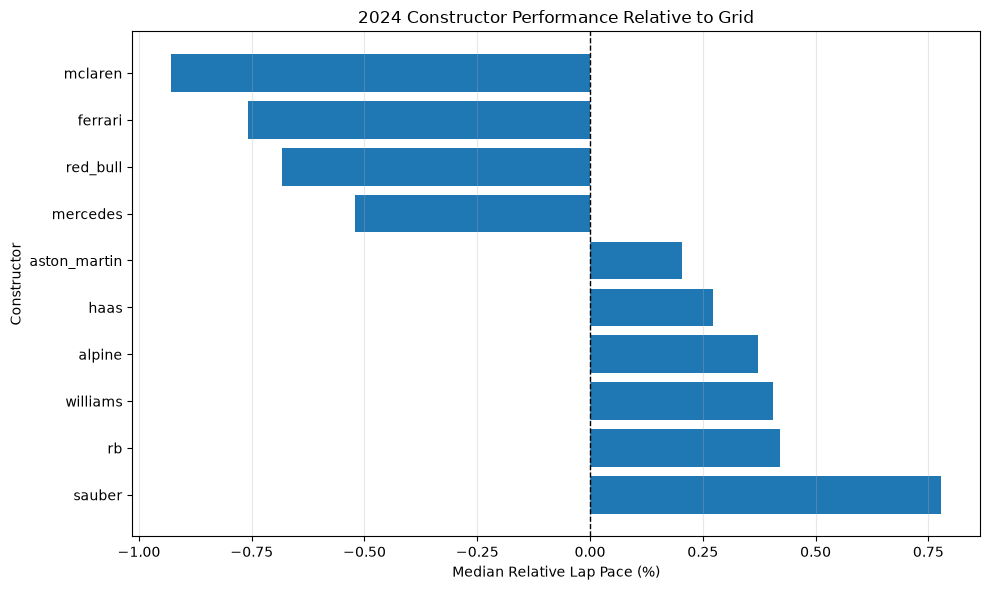

In [13]:

# GRAPH 1 - 2024 CONSTRUCTOR PERFORMANCE

plot_data = constructor_summary.sort_values(
    "median_relative_pct",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["constructor_id"],
    plot_data["median_relative_pct"]
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Median Relative Lap Pace (%)")
plt.ylabel("Constructor")
plt.title("2024 Constructor Performance Relative to Grid")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Consistency across the 2024 season

A horizontal boxplot summarizes each team's distribution of relative pace over its **eligible races**. Narrower boxes mean less between-race variation in this metric; differences in circuit mix and race coverage can also change box width.

Constructors: 10
constructor_id  median_relative_pct  races
       mclaren            -0.929581     24
       ferrari            -0.758811     24
      red_bull            -0.682148     21
      mercedes            -0.521756     23
  aston_martin             0.202931     20
          haas             0.273125     23
        alpine             0.372063     20
      williams             0.405951     19
            rb             0.420290     21
        sauber             0.778982     22


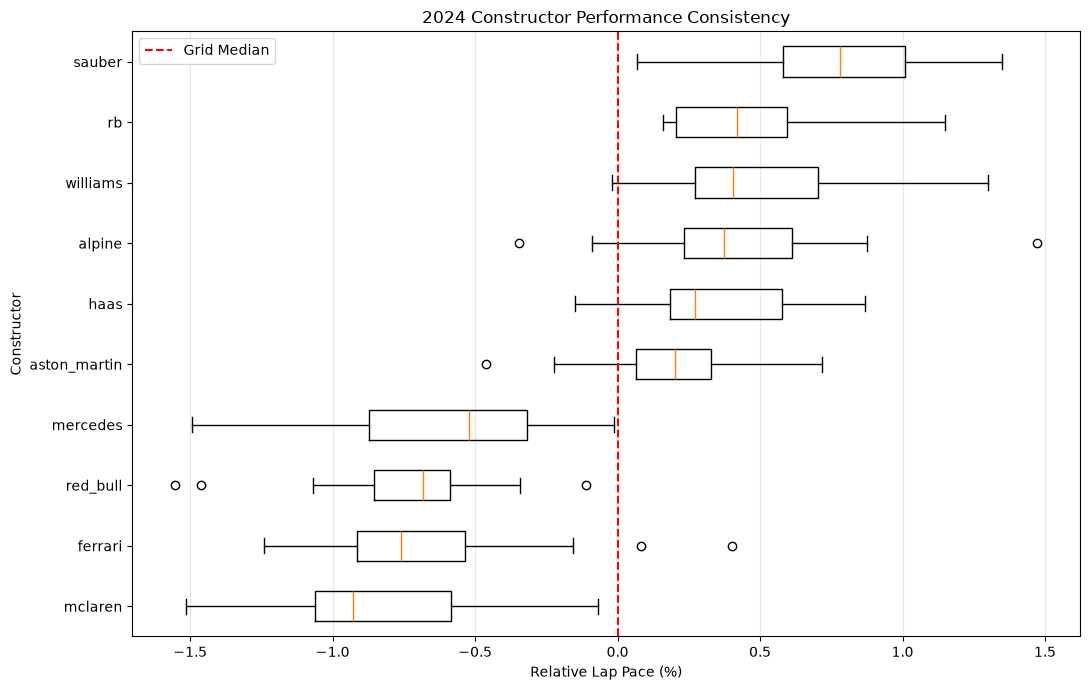

In [14]:

# GRAPH 2 - CONSTRUCTOR CONSISTENCY (2024)

import matplotlib.pyplot as plt

season_2024 = team_race[
    team_race["season"] == 2024
].copy()

# Recalculate summary to include every eligible team
constructor_summary = (
    season_2024.groupby("constructor_id", as_index=False)
    .agg(
        median_relative_pct=("team_relative_pct", "median"),
        races=("round", "nunique")
    )
    .sort_values("median_relative_pct")
)

print("Constructors:", len(constructor_summary))
print(constructor_summary.to_string(index=False))

if len(constructor_summary) != 10:
    raise ValueError(
        "Expected 10 constructors for 2024. "
        "Check the team_race dataset."
    )

# Compare distributions across races
teams = constructor_summary["constructor_id"].tolist()

distributions = [
    season_2024.loc[
        season_2024["constructor_id"] == team,
        "team_relative_pct"
    ].values
    for team in teams
]

plt.figure(figsize=(11, 7))

plt.boxplot(
    distributions,
    tick_labels=teams,
    orientation="horizontal",
    showfliers=True
)

plt.axvline(
    0, color="red", linestyle="--",
    label="Grid Median"
)

plt.xlabel("Relative Lap Pace (%)")
plt.ylabel("Constructor")
plt.title("2024 Constructor Performance Consistency")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Conclusion — Constructor / Car Performance

Among the analyzed 2024 constructor-race observations, **McLaren** had the fastest median relative pace (**−0.930%**), followed by **Ferrari (−0.759%)**, **Red Bull (−0.682%)** and **Mercedes (−0.522%)**. In the consistency boxplot, Red Bull's central range was relatively narrow while Mercedes showed greater between-race variation.

**Takeaway:** constructor affiliation is associated with different observed lap-time performance. This is **not** a measurement of the car's isolated effect: drivers, race tactics and other conditions contribute. Because eligibility rules leave different numbers of races per team (for example, McLaren 24 and Red Bull 21), rankings are exploratory rather than strictly like-for-like.

---

## 4. Race Progression

**Question:** Do lap times change systematically over a race?

**Method:** Express a driver's lap as a percentage of the highest recorded lap number in that race. Keep drivers who reached at least **90%** of the recorded race laps. Compare each selected lap with the median of that driver's selected laps for the same race, then summarize within ten race-progress bins. This permits comparisons across races of different lengths without mixing absolute lap times.

In [15]:

# ANALYSIS 4 - RACE PROGRESSION

import pandas as pd
import matplotlib.pyplot as plt

race_keys = ["season", "round"]
driver_keys = ["season", "round", "driver_id"]

# Maximum recorded lap in each race
race_max = (
    features.groupby(race_keys)["lap"]
    .max()
    .rename("race_max_lap")
)

# Maximum lap reached by each driver
driver_max = (
    features.groupby(driver_keys)["lap"]
    .max()
    .rename("driver_max_lap")
)

progress_data = pace_laps.copy()

progress_data = progress_data.join(
    race_max, on=race_keys
)

progress_data = progress_data.join(
    driver_max, on=driver_keys
)

# Focus on drivers who reached at least 90%
# of the maximum recorded race lap
progress_data = progress_data[
    progress_data["driver_max_lap"]
    >= 0.90 * progress_data["race_max_lap"]
].copy()

# Calculate race progression percentage
progress_data["race_progress_pct"] = (
    progress_data["lap"]
    / progress_data["race_max_lap"]
) * 100

# Driver's typical lap time in that race
progress_data["driver_race_median"] = (
    progress_data.groupby(driver_keys)["lap_time_seconds"]
    .transform("median")
)

# Relative lap time (%)
progress_data["relative_lap_pct"] = (
    (
        progress_data["lap_time_seconds"]
        / progress_data["driver_race_median"]
    ) - 1
) * 100

# Divide each race into 10 phases
bins = list(range(0, 101, 10))

labels = [
    f"{i}-{i+10}%"
    for i in range(0, 100, 10)
]

progress_data["race_phase"] = pd.cut(
    progress_data["race_progress_pct"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# One median per driver, race and phase
driver_phase = (
    progress_data.groupby(
        driver_keys + ["race_phase"],
        observed=True,
        as_index=False
    )
    .agg(
        median_relative_pct=("relative_lap_pct", "median"),
        n_laps=("lap", "size")
    )
)

# Overall summary of race progression
progress_summary = (
    driver_phase.groupby("race_phase", observed=True)
    .agg(
        median_relative_pct=("median_relative_pct", "median"),
        observations=("median_relative_pct", "size")
    )
    .reset_index()
)

if progress_summary.empty:
    raise ValueError("No race progression data available.")

print("RACE PROGRESSION ANALYSIS PASSED!")

print("\nRace progression summary:")
print(progress_summary.to_string(index=False))


RACE PROGRESSION ANALYSIS PASSED!

Race progression summary:
race_phase  median_relative_pct  observations
     0-10%             1.431974          8943
    10-20%             0.940114          9355
    20-30%             0.539176          9435
    30-40%             0.266058          9432
    40-50%             0.049163          9446
    50-60%            -0.167902          9477
    60-70%            -0.455665          9422
    70-80%            -0.650123          9451
    80-90%            -0.826681          9454
   90-100%            -0.742481          9450


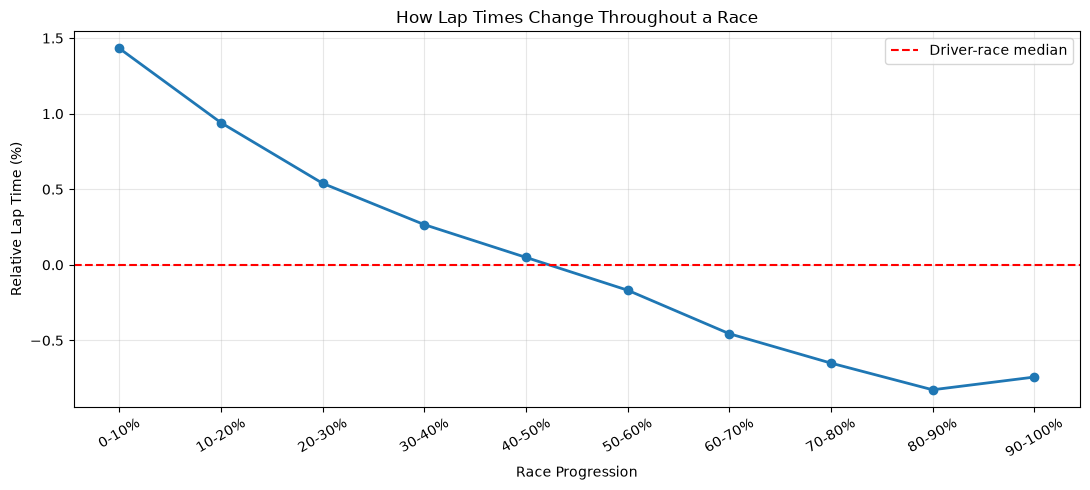

In [16]:

# GRAPH 1 - RACE PROGRESSION

plt.figure(figsize=(11, 5))

plt.plot(
    progress_summary["race_phase"].astype(str),
    progress_summary["median_relative_pct"],
    marker="o",
    linewidth=2
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Driver-race median"
)

plt.xlabel("Race Progression")
plt.ylabel("Relative Lap Time (%)")
plt.title("How Lap Times Change Throughout a Race")

plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Conclusion — Race Progression

Relative lap times generally **decreased over the course of a race** in the selected sample. The first **0–10%** of race distance was about **+1.43%** slower than each driver's race median; during the last **90–100%** the median was about **−0.75%** relative to that reference.

**Takeaway:** later race phases were generally associated with faster laps. Reduced fuel load is a plausible explanation, but pit strategy, tire changes and degradation, track evolution, traffic and race-control events were not independently modeled, so no single cause can be established.

---

## Overall Findings

| Factor | Main finding from this exploratory analysis | Caution |
|---|---|---|
| Circuit length | Positive correlation with absolute lap time (**r = 0.756**) | More distance naturally takes more time |
| Circuit turns / type | Weak turns association (**r = 0.087**); street circuits slightly slower per km | Historical layout and corner difficulty not controlled |
| Driver | Typical matched teammate laps differ (**median absolute gap 0.611 s**) | Tires, traffic and strategy remain confounders |
| Constructor/team | Different 2024 relative paces; McLaren was fastest by this metric | Team results are not pure car effects |
| Race progression | Relative lap times generally fall over a race | Fuel and tire mechanisms cannot be isolated |
